# Lab Manual 2 — Data Analysis and Visualization
### Dataset: Adult Income

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df = pd.read_csv('adult.csv')
df.replace('?', np.nan, inplace=True)
df.dropna(inplace=True)
df.to_csv('adult_cleaned.csv', index=False)

## Task 1

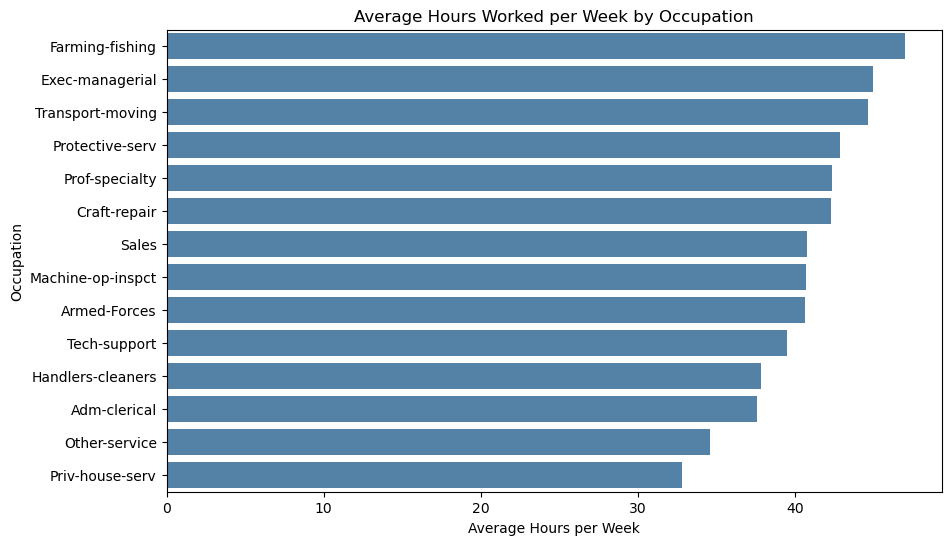

In [27]:
avg_hours_by_occ = df.groupby('occupation')['hours.per.week'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=avg_hours_by_occ.values, y=avg_hours_by_occ.index, color='steelblue')
plt.xlabel('Average Hours per Week')
plt.ylabel('Occupation')
plt.title('Average Hours Worked per Week by Occupation')
plt.show()

## Task 2

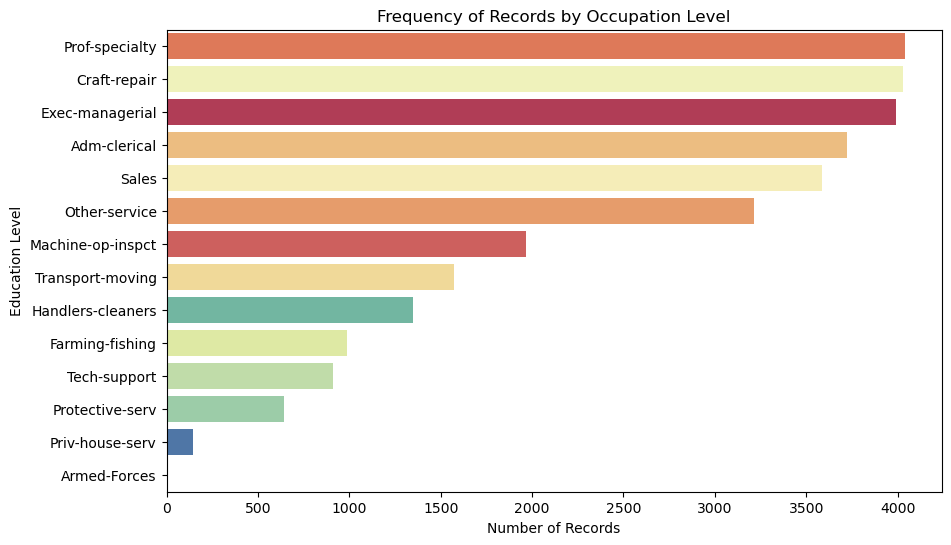

Most common category: Prof-specialty


In [28]:
order = df['occupation'].value_counts().index

plt.figure(figsize=(10, 6))
sns.countplot(data=df, y='occupation', order=order, hue='occupation',palette='Spectral')
plt.xlabel('Number of Records')
plt.ylabel('Education Level')
plt.title('Frequency of Records by Occupation Level')
plt.show()

print("Most common category:", df['occupation'].value_counts().idxmax())

## Task 3

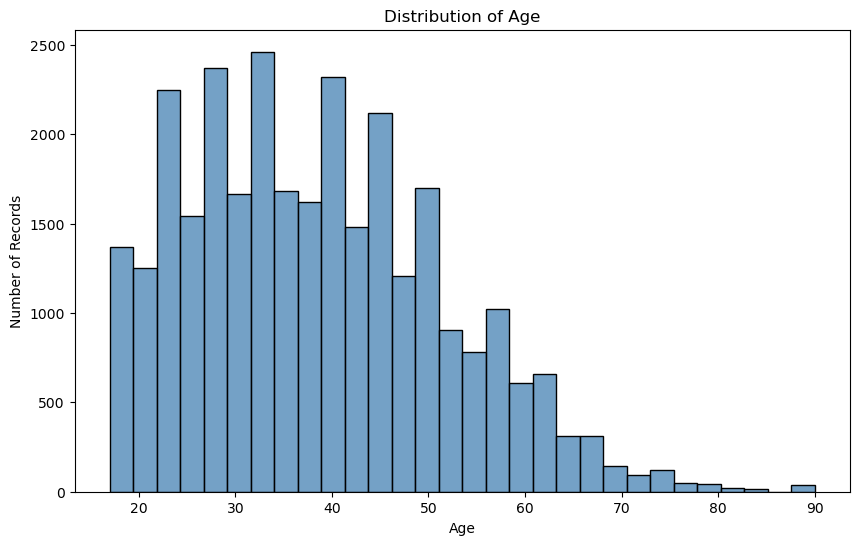

Mean: 38.437901995888865 Median: 37.0
Right-skewed bcz most vals are in the younger ages creating a long tail towards older age


In [29]:
plt.figure(figsize=(10, 6))
sns.histplot(df['age'], bins=30, color='steelblue')
plt.xlabel('Age')
plt.ylabel('Number of Records')
plt.title('Distribution of Age')
plt.show()

print("Mean:", df['age'].mean(), "Median:", df['age'].median())
print("Right-skewed bcz most vals are in the younger ages creating a long tail towards older age")

## Task 4

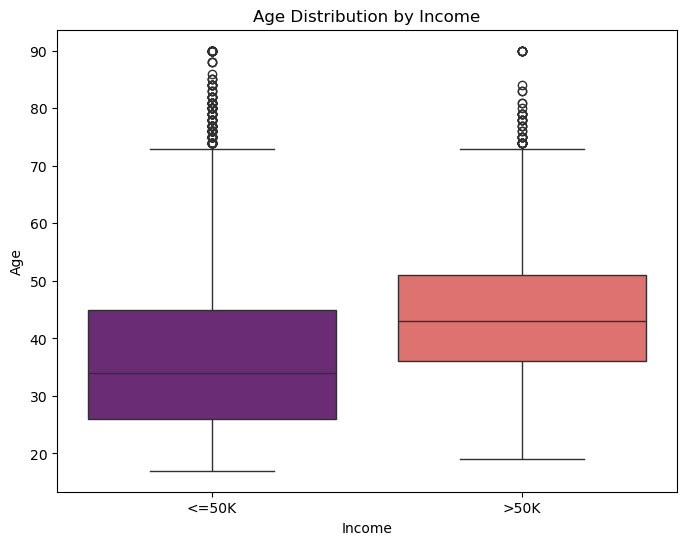

In [30]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='income', y='age',hue='income',palette='magma')
plt.xlabel('Income')
plt.ylabel('Age')
plt.title('Age Distribution by Income')
plt.show()

## Task 5

In [38]:
Q1 = df['age'].quantile(0.25)
Q3 = df['age'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['age'] < lower) | (df['age'] > upper)]
print(len(outliers))

print("\nThis matches the count visually estimated from the Task 4, "
      "since both use the exact same 1.5xIQR rule. The box plot is simply a picture of this calculation.")

169

This matches the count visually estimated from the Task 4, since both use the exact same 1.5xIQR rule. The box plot is simply a picture of this calculation.


## Task 6

In [40]:
mean = df['age'].mean()
std = df['age'].std()
df['zscore'] = (df['age'] - mean) / std

outliers_z = df[df['zscore'].abs() > 3]
print(len(outliers_z))


print(f"""
Comparison: Z-score flags {len(outliers_z)} outliers versus {len(outliers)} flagged by IQR.
Age is right-skewed, not symmetric around the mean. Z-score assumes a roughly
normal, symmetric distribution, so on skewed data like age it tends to flag fewer values as
extreme (the tail on the high side inflates the standard deviation, widening the "normal"
range) than the quartile-based IQR method, which makes no distributional assumption.
""")

120

Comparison: Z-score flags 120 outliers versus 169 flagged by IQR.
Age is right-skewed, not symmetric around the mean. Z-score assumes a roughly
normal, symmetric distribution, so on skewed data like age it tends to flag fewer values as
extreme (the tail on the high side inflates the standard deviation, widening the "normal"
range) than the quartile-based IQR method, which makes no distributional assumption.



## Task 7

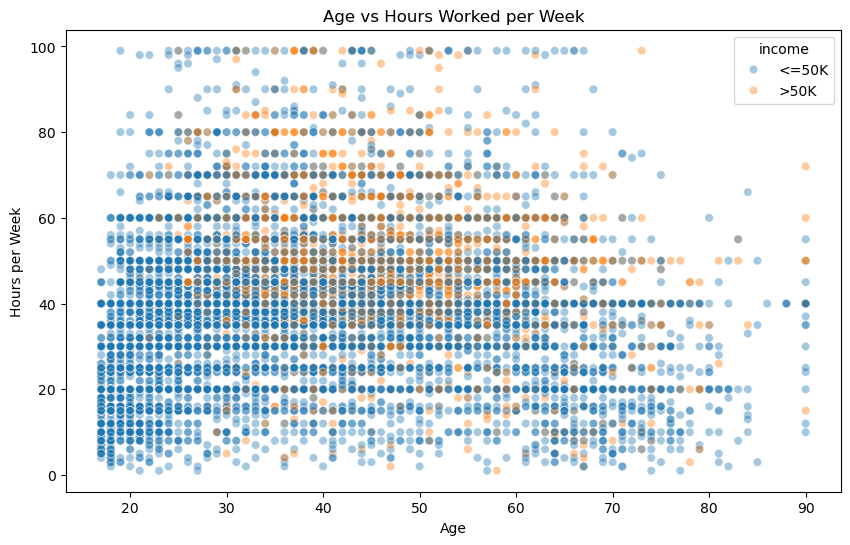

There is only a weak positive relationship overall (points are spread widely across ages at ~40 hrs/week), but the >50K group is visibly clustered at higher hours and mid-range ages (30s-50s) compared to the <=50K group, which is more scattered across ages and hours.


In [41]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='age', y='hours.per.week', hue='income', alpha=0.4)
plt.xlabel('Age')
plt.ylabel('Hours per Week')
plt.title('Age vs Hours Worked per Week')
plt.show()
print("There is only a weak positive relationship overall (points are spread widely across ages "
      "at ~40 hrs/week), but the >50K group is visibly clustered at higher hours and mid-range "
      "ages (30s-50s) compared to the <=50K group, which is more scattered across ages and hours.")

## Task 8

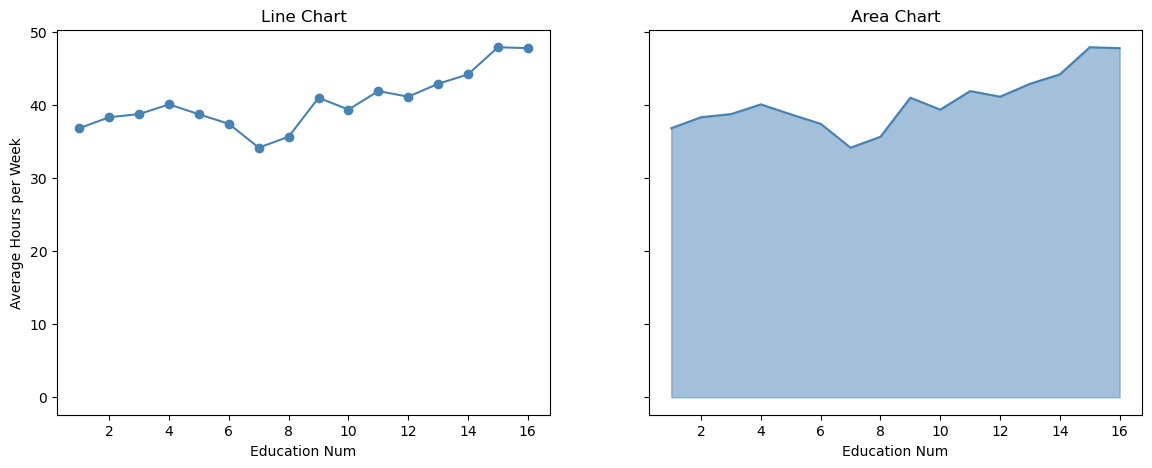

The line chart shows the trend clearly: average hours worked rises steadily with education level. The area chart shows the exact same trend, but the filled region draws extra visual attention to the magnitude/volume under the curve, which can make the increase look more dramatic even though the underlying numbers are identical.


In [42]:
avg_by_edu = df.groupby('education.num')['hours.per.week'].mean().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

axes[0].plot(avg_by_edu.index, avg_by_edu.values, marker='o', color='steelblue')
axes[0].set_title('Line Chart')
axes[0].set_xlabel('Education Num')
axes[0].set_ylabel('Average Hours per Week')

axes[1].fill_between(avg_by_edu.index, avg_by_edu.values, color='steelblue', alpha=0.5)
axes[1].plot(avg_by_edu.index, avg_by_edu.values, color='steelblue')
axes[1].set_title('Area Chart')
axes[1].set_xlabel('Education Num')

plt.show()

print("The line chart shows the trend clearly: average hours worked rises steadily with "
      "education level. The area chart shows the exact same trend, but the filled region "
      "draws extra visual attention to the magnitude/volume under the curve, which can make "
      "the increase look more dramatic even though the underlying numbers are identical.")

## Task 9

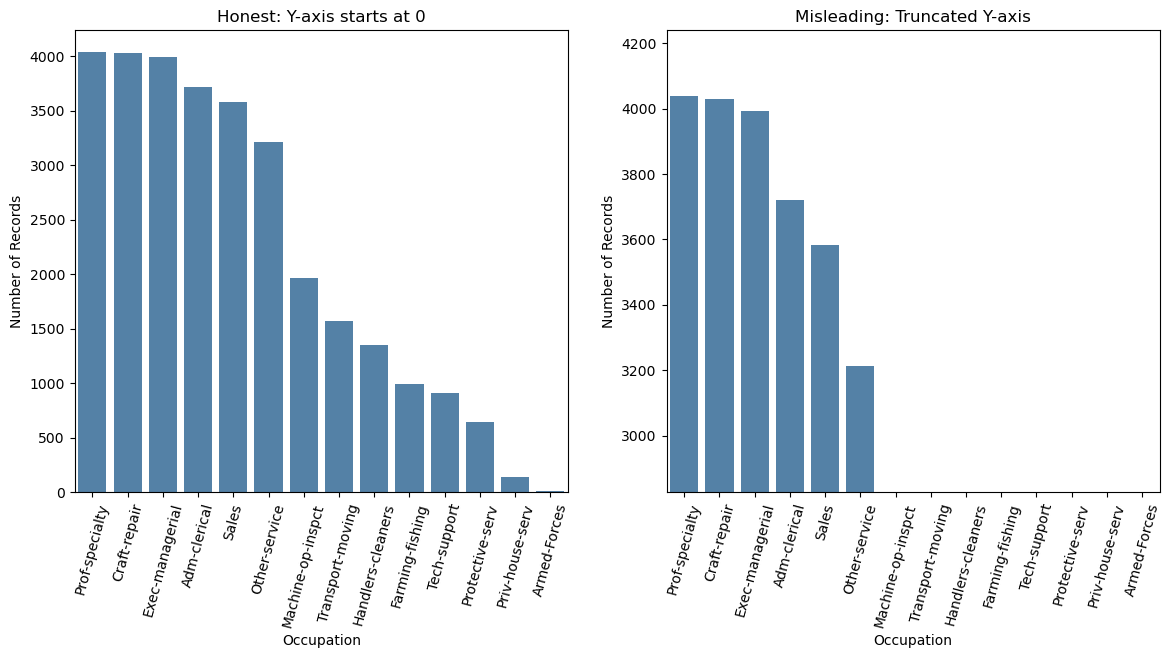


Comparison: In the honest chart (axis starting at 0), the bars for top categories like Prof-specialty and Exec-managerial 
look proportionally larger than smaller ones like Armed-Forces or Priv-house-serv, but the differences appear reasonable 
relative to true scale. In the truncated chart, the y-axis starts well above zero, causing the smaller categories to 
completely vanish while the visual gap between the top categories is hugely exaggerated — even though the underlying 
counts haven't changed at all. This is exactly the kind of graphical integrity violation the manual warns about: 
proportions on the page no longer match proportions in the data, which misleads a viewer into overestimating how much 
more common some occupations are than others.



In [45]:
occ_counts = df['occupation'].value_counts().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(x=occ_counts.index, y=occ_counts.values, color='steelblue', ax=axes[0])
axes[0].set_title('Honest: Y-axis starts at 0')
axes[0].set_xlabel('Occupation')
axes[0].set_ylabel('Number of Records')
axes[0].tick_params(axis='x', rotation=75)

sns.barplot(x=occ_counts.index, y=occ_counts.values, color='steelblue', ax=axes[1])
axes[1].set_ylim(bottom=0.7 * occ_counts.max())
axes[1].set_title('Misleading: Truncated Y-axis')
axes[1].set_xlabel('Occupation')
axes[1].set_ylabel('Number of Records')
axes[1].tick_params(axis='x', rotation=75)

plt.show()

print("""
Comparison: In the honest chart (axis starting at 0), the bars for top categories like Prof-specialty and Exec-managerial 
look proportionally larger than smaller ones like Armed-Forces or Priv-house-serv, but the differences appear reasonable 
relative to true scale. In the truncated chart, the y-axis starts well above zero, causing the smaller categories to 
completely vanish while the visual gap between the top categories is hugely exaggerated — even though the underlying 
counts haven't changed at all. This is exactly the kind of graphical integrity violation the manual warns about: 
proportions on the page no longer match proportions in the data, which misleads a viewer into overestimating how much 
more common some occupations are than others.
""")